In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mp
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score, roc_auc_score,
                             average_precision_score, ConfusionMatrixDisplay)

df = pd.read_csv("health_data.csv")
target = "Is_Fraud"
numeric_cols = ["Claim_Amount", "Patient_Age", "No_of_Claims_Provider", "Service_Claim_days",
                "Length_of_Stay", "Prior_Visits_12m", "Chronic_Condition_Flag"]
categorical_cols = ["Insurance_Type", "Patient_Gender", "Provider_Specialty", "Visit_Type",
                    "State", "Diagnosis_Code", "Procedure_Code"]

X_raw = df[numeric_cols + categorical_cols].copy()
y = df[target]
X_raw["Provider_Specialty"] = X_raw["Provider_Specialty"].fillna("Unknown")
X_raw[categorical_cols] = X_raw[categorical_cols].astype(str)
pd.concat([X_raw, y], axis=1).to_csv("ab_prepared_data.csv", index=False)   
print("Rows, predictors:", X_raw.shape)

Rows, predictors: (10000, 14)


Train/test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y)
print("Rows shared by train and test:", len(set(X_train.index) & set(X_test.index)))  
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Fraud in train:", y_train.sum(), "| fraud in test:", y_test.sum())

Rows shared by train and test: 0
Train: (8000, 14) Test: (2000, 14)
Fraud in train: 663 | fraud in test: 166


One-hot encoding

In [3]:
X_train_oh = pd.get_dummies(X_train, columns=categorical_cols, dtype=int)
X_test_oh = pd.get_dummies(X_test, columns=categorical_cols, dtype=int).reindex(
    columns=X_train_oh.columns, fill_value=0)
print("Encoded features:", X_train_oh.shape[1])

# Before and after for one column
before_after = X_train[["Insurance_Type"]].head(3).join(X_train_oh.filter(like="Insurance_Type_").head(3))
print(before_after.to_string())

Encoded features: 51
     Insurance_Type  Insurance_Type_Medicaid  Insurance_Type_Medicare  Insurance_Type_Other  Insurance_Type_Private  Insurance_Type_Self-Pay
9326       Medicaid                        1                        0                     0                       0                        0
5375        Private                        0                        0                     0                       1                        0
1146       Self-Pay                        0                        0                     0                       0                        1


Data prep figures

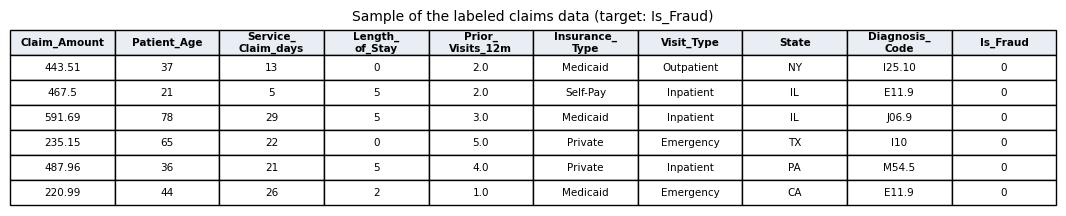

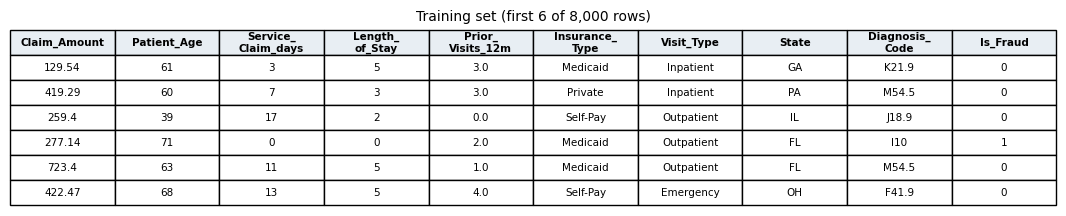

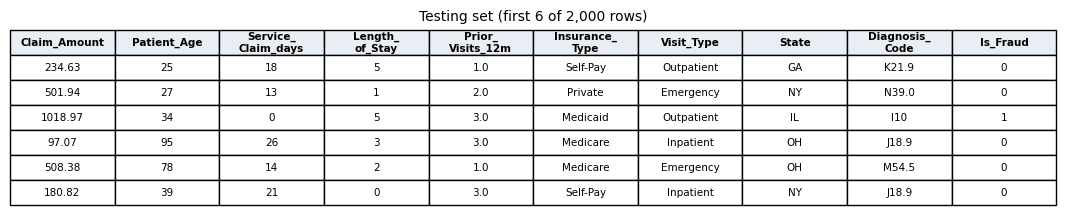

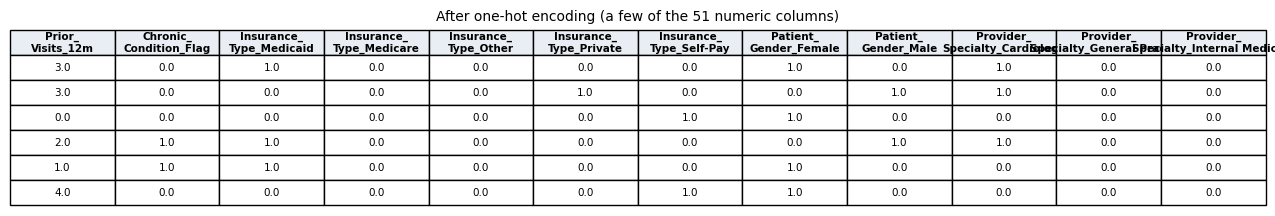

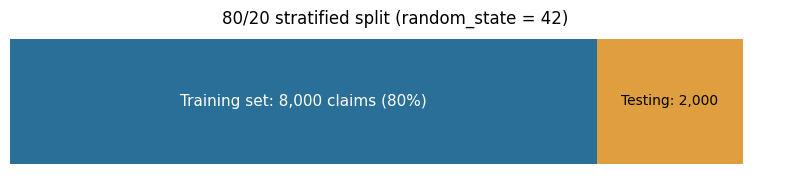

In [4]:
def table_png(frame, path, title):
    f = frame.head(6)
    fig, ax = plt.subplots(figsize=(min(1.35 * len(f.columns), 20), 2.3)); ax.axis("off")
    t = ax.table(cellText=f.round(2).values,
                 colLabels=[c.replace("_", "_\n", 1) if len(c) > 12 else c for c in f.columns],
                 loc="center", cellLoc="center")
    t.auto_set_font_size(False); t.set_fontsize(7.5); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        if r == 0: cell.set_facecolor("#e8eef3"); cell.set_text_props(weight="bold")
    ax.set_title(title, fontsize=10); plt.savefig(path, dpi=200, bbox_inches="tight"); plt.show()

show_cols = ["Claim_Amount", "Patient_Age", "Service_Claim_days", "Length_of_Stay", "Prior_Visits_12m",
             "Insurance_Type", "Visit_Type", "State", "Diagnosis_Code"]
full = pd.concat([X_raw, y], axis=1)
table_png(full[show_cols + ["Is_Fraud"]], "ab_data_sample.png", "Sample of the labeled claims data (target: Is_Fraud)")
table_png(pd.concat([X_train, y_train], axis=1)[show_cols + ["Is_Fraud"]], "ab_train_sample.png", "Training set (first 6 of 8,000 rows)")
table_png(pd.concat([X_test, y_test], axis=1)[show_cols + ["Is_Fraud"]], "ab_test_sample.png", "Testing set (first 6 of 2,000 rows)")

# One-hot encoded sample
table_png(X_train_oh.iloc[:, 5:17], "ab_encoded_sample.png", "After one-hot encoding (a few of the 51 numeric columns)")

fig, ax = plt.subplots(figsize=(8, 1.9))
ax.barh([0], [8000], color="#2a6f97"); ax.barh([0], [2000], left=[8000], color="#e09f3e")
ax.text(4000, 0, "Training set: 8,000 claims (80%)", ha="center", va="center", color="white", fontsize=11)
ax.text(9000, 0, "Testing: 2,000", ha="center", va="center", fontsize=10)
ax.axis("off"); ax.set_title("80/20 stratified split (random_state = 42)")
plt.tight_layout(); plt.savefig("ab_train_test_split.png", dpi=200); plt.show()

This holds out a quarter of the training set, so the test set stays untouched.

/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


learning rate 0.05: best validation accuracy 0.9400 at round 159; at round 400: 0.9400


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


learning rate 0.1: best validation accuracy 0.9535 at round 276; at round 400: 0.9530


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


learning rate 0.5: best validation accuracy 0.9545 at round 75; at round 400: 0.9540
learning rate 1.0: best validation accuracy 0.9535 at round 100; at round 400: 0.9510


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


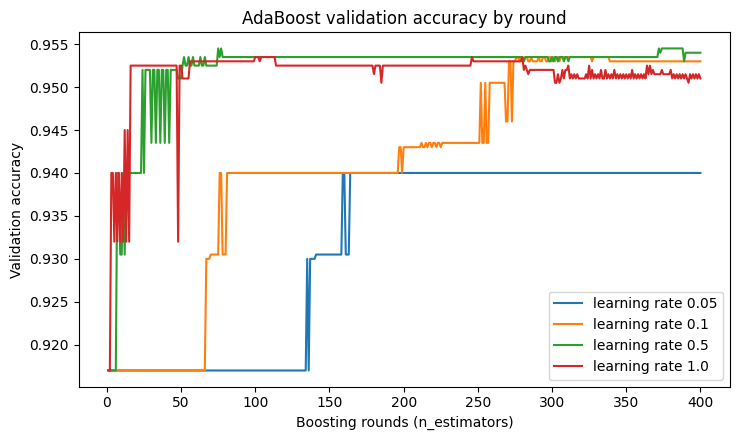

In [5]:
stump = lambda: DecisionTreeClassifier(max_depth=1, random_state=42)

Xa, Xv, ya, yv = train_test_split(X_train_oh, y_train, test_size=0.25, random_state=42, stratify=y_train)
rounds = 400
curves = {}
for lr in [0.05, 0.1, 0.5, 1.0]:
    m = AdaBoostClassifier(estimator=stump(), n_estimators=rounds, learning_rate=lr,
                           random_state=42).fit(Xa, ya)
    curves[lr] = [accuracy_score(yv, p) for p in m.staged_predict(Xv)]
    best = int(np.argmax(curves[lr]))
    print(f"learning rate {lr}: best validation accuracy {max(curves[lr]):.4f} at round {best + 1}; at round 400: {curves[lr][-1]:.4f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for lr, c in curves.items():
    ax.plot(range(1, rounds + 1), c, label=f"learning rate {lr}")
ax.set_xlabel("Boosting rounds (n_estimators)"); ax.set_ylabel("Validation accuracy")
ax.set_title("AdaBoost validation accuracy by round"); ax.legend()
plt.tight_layout(); plt.savefig("ab_validation_curve.png", dpi=200); plt.show()

Tune n_estimators and learning_rate with 5-fold CV on the training set

In [6]:
param_grid = {"n_estimators": [50, 100, 200, 400], "learning_rate": [0.05, 0.1, 0.5, 1.0]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(AdaBoostClassifier(estimator=stump(), random_state=42), param_grid,
                    cv=cv, scoring="average_precision", n_jobs=-1)
grid.fit(X_train_oh, y_train)
print("Best parameters:", grid.best_params_)
print("Best CV PR AUC:", round(grid.best_score_, 3))
res = pd.DataFrame(grid.cv_results_)[["param_n_estimators", "param_learning_rate", "mean_test_score"]]
print(res.pivot(index="param_learning_rate", columns="param_n_estimators", values="mean_test_score").round(3))

Best parameters: {'learning_rate': 0.5, 'n_estimators': 400}
Best CV PR AUC: 0.786
param_n_estimators     50     100    200    400
param_learning_rate                            
0.05                 0.339  0.480  0.688  0.754
0.10                 0.521  0.687  0.755  0.770
0.50                 0.752  0.765  0.774  0.786
1.00                 0.745  0.773  0.785  0.785


Final model on the test set

In [7]:
model = grid.best_estimator_
pred = model.predict(X_test_oh)
prob = model.predict_proba(X_test_oh)[:, 1]
cm = confusion_matrix(y_test, pred)
tn, fp, fn, tp = cm.ravel()
print(cm)
print(classification_report(y_test, pred, digits=3))
print("Accuracy", round(accuracy_score(y_test, pred), 4), "| ROC AUC", round(roc_auc_score(y_test, prob), 3),
      "| PR AUC", round(average_precision_score(y_test, prob), 3))
print("Specificity", round(tn / (tn + fp), 4), "| FP", fp, "| FN", fn,
      "| Precision", round(tp / (tp + fp), 4), "| Recall", round(tp / (tp + fn), 4))
print("Baseline (all legitimate) accuracy:", round(1 - y_test.mean(), 4))

imp = pd.Series(model.feature_importances_, index=X_train_oh.columns).sort_values(ascending=False)
print("\nFeature importances:"); print(imp.head(8).round(4))
print("\nFirst 5 stump weights (alpha):", model.estimator_weights_[:5].round(3))
print("First 5 stump errors:", model.estimator_errors_[:5].round(3))

[[1806   28]
 [  60  106]]
              precision    recall  f1-score   support

           0      0.968     0.985     0.976      1834
           1      0.791     0.639     0.707       166

    accuracy                          0.956      2000
   macro avg      0.879     0.812     0.841      2000
weighted avg      0.953     0.956     0.954      2000

Accuracy 0.956 | ROC AUC 0.973 | PR AUC 0.803
Specificity 0.9847 | FP 28 | FN 60 | Precision 0.791 | Recall 0.6386
Baseline (all legitimate) accuracy: 0.917

Feature importances:
Service_Claim_days                0.8192
Claim_Amount                      0.1340
No_of_Claims_Provider             0.0380
Diagnosis_Code_F41.9              0.0042
State_PA                          0.0026
Provider_Specialty_Pulmonology    0.0021
Diagnosis_Code_J18.9              0.0000
State_OH                          0.0000
dtype: float64

First 5 stump weights (alpha): [1.202 0.925 0.72  0.587 0.484]
First 5 stump errors: [0.083 0.136 0.192 0.236 0.275]


Confusion matrix and importance figures

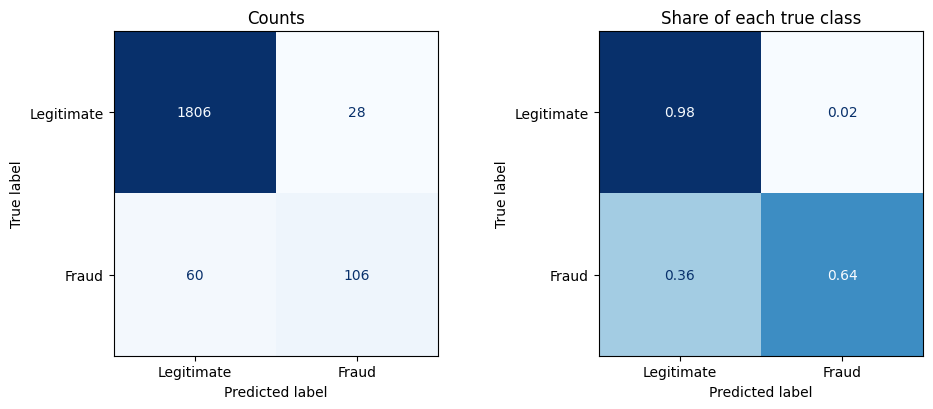

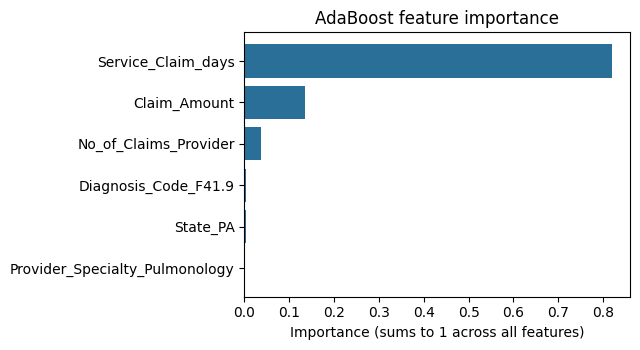

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Legitimate", "Fraud"]).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Counts")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=["Legitimate", "Fraud"]).plot(
    ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
ax[1].set_title("Share of each true class")
plt.tight_layout(); plt.savefig("ab_confusion_matrix.png", dpi=200); plt.show()

top = imp.head(6)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(top.index, top.values, color="#2a6f97")
ax.set_xlabel("Importance (sums to 1 across all features)"); ax.set_title("AdaBoost feature importance")
plt.tight_layout(); plt.savefig("ab_importance.png", dpi=200); plt.show()

For the Overview images

bagging vs boosting

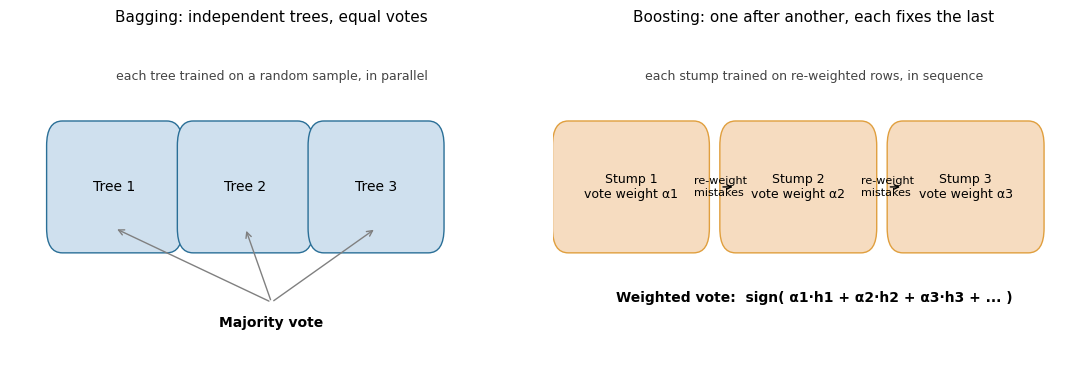

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a in ax:
    a.axis("off"); a.set_xlim(0, 10); a.set_ylim(0, 4)
ax[0].set_title("Bagging: independent trees, equal votes", fontsize=11)
for i, x in enumerate([1, 3.5, 6]):
    ax[0].add_patch(mp.FancyBboxPatch((x, 1.6), 2, 1, boxstyle="round", fc="#cfe0ee", ec="#2a6f97"))
    ax[0].text(x + 1, 2.1, f"Tree {i+1}", ha="center", va="center")
    ax[0].annotate("", (x + 1, 1.6), (5, 0.7), arrowprops=dict(arrowstyle="->", color="gray"))
ax[0].text(5, 0.4, "Majority vote", ha="center", fontweight="bold")
ax[0].text(5, 3.4, "each tree trained on a random sample, in parallel", ha="center", fontsize=9, color="#444")
ax[1].set_title("Boosting: one after another, each fixes the last", fontsize=11)
for i, x in enumerate([0.3, 3.5, 6.7]):
    ax[1].add_patch(mp.FancyBboxPatch((x, 1.6), 2.4, 1, boxstyle="round", fc="#f6dcc0", ec="#e09f3e"))
    ax[1].text(x + 1.2, 2.1, f"Stump {i+1}\nvote weight α{i+1}", ha="center", va="center", fontsize=9)
    if i < 2:
        ax[1].annotate("re-weight\nmistakes", (x + 3.2, 2.1), (x + 2.4, 2.1),
                       arrowprops=dict(arrowstyle="->"), ha="left", va="center", fontsize=8)
ax[1].text(5, 0.7, "Weighted vote:  sign( α1·h1 + α2·h2 + α3·h3 + ... )", ha="center", fontweight="bold")
ax[1].text(5, 3.4, "each stump trained on re-weighted rows, in sequence", ha="center", fontsize=9, color="#444")
plt.tight_layout(); plt.savefig("ab_bagging_vs_boosting.png", dpi=200); plt.show()

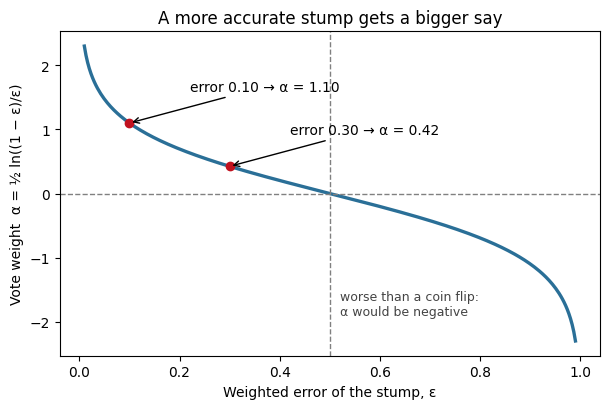

In [10]:
e = np.linspace(0.01, 0.99, 300)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot(e, 0.5 * np.log((1 - e) / e), color="#2a6f97", lw=2.4)
ax.axhline(0, color="gray", ls="--", lw=1); ax.axvline(0.5, color="gray", ls="--", lw=1)
for ee, lab in [(0.1, "error 0.10 → α = 1.10"), (0.3, "error 0.30 → α = 0.42")]:
    a = 0.5 * np.log((1 - ee) / ee)
    ax.scatter([ee], [a], color="#c1121f", zorder=3)
    ax.annotate(lab, (ee, a), (ee + 0.12, a + 0.5), arrowprops=dict(arrowstyle="->"))
ax.text(0.52, -1.9, "worse than a coin flip:\nα would be negative", fontsize=9, color="#444")
ax.set_xlabel("Weighted error of the stump, ε"); ax.set_ylabel("Vote weight  α = ½ ln((1 − ε)/ε)")
ax.set_title("A more accurate stump gets a bigger say")
plt.tight_layout(); plt.savefig("ab_alpha_curve.png", dpi=200); plt.show()

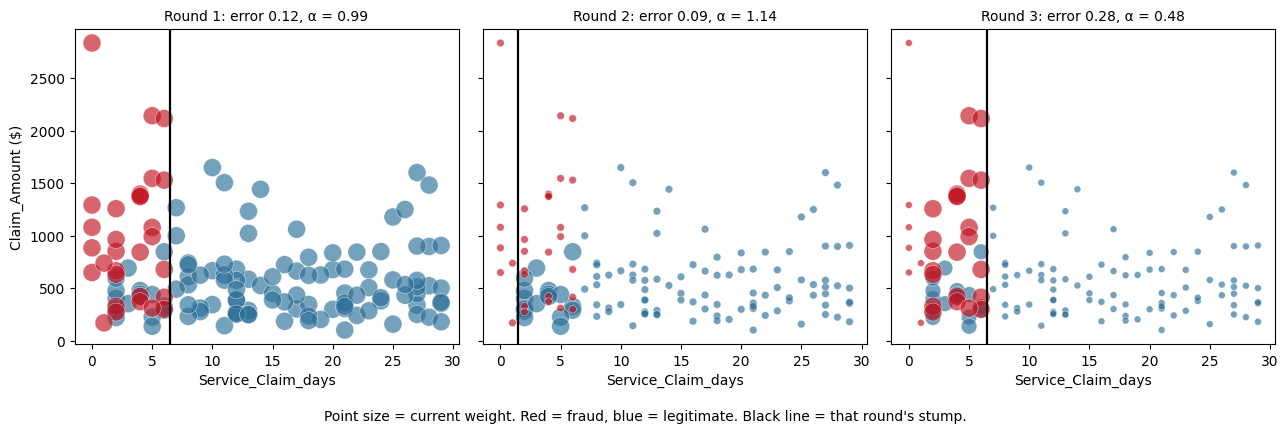

In [ ]:
tr = pd.concat([X_train, y_train], axis=1)
s = pd.concat([tr[tr.Is_Fraud == 0].sample(110, random_state=1),
               tr[tr.Is_Fraud == 1].sample(30, random_state=1)])     
F = s[["Service_Claim_days", "Claim_Amount"]].values
yy = np.where(s.Is_Fraud.values == 1, 1, -1)
w = np.ones(len(yy)) / len(yy)

fig, ax = plt.subplots(1, 3, figsize=(13, 4.3), sharey=True)
for r in range(3):
    st = DecisionTreeClassifier(max_depth=1, random_state=0).fit(F, yy, sample_weight=w)
    p = st.predict(F)
    err = w[p != yy].sum()
    alpha = 0.5 * np.log((1 - err) / err)
    ax[r].scatter(F[:, 0], F[:, 1], s=w / w.max() * 160 + 8, c=np.where(yy == 1, "#c1121f", "#2a6f97"),
                  alpha=0.65, edgecolor="white", lw=0.4)
    f, t = st.tree_.feature[0], st.tree_.threshold[0]
    (ax[r].axvline if f == 0 else ax[r].axhline)(t, color="black", lw=1.6)
    ax[r].set_title(f"Round {r+1}: error {err:.2f}, α = {alpha:.2f}", fontsize=10)
    ax[r].set_xlabel("Service_Claim_days")
    w = w * np.exp(-alpha * yy * p); w /= w.sum()                
ax[0].set_ylabel("Claim_Amount ($)")
fig.text(0.5, 0.01, "Point size = current weight. Red = fraud, blue = legitimate. Black line = that round's stump.",
         ha="center", fontsize=10)
plt.tight_layout(rect=[0, 0.05, 1, 1]); plt.savefig("ab_reweighting.png", dpi=200); plt.show()